# AgroGuard — EDA + Treino Isolation Forest por Componente

**Challenge FIAP Next 2026** · Trator John Deere Série 6M

Pipeline completo da **etapa 3** (Algoritmo de Componentes):

1. **Carregamento** dos 3 equipamentos simulados
2. **EDA** — qualidade, distribuições, correlações, multimodalidade por regime, padrões temporais e visão das anomalias
3. **Melhoria dos dados** — feature engineering temporal (janela móvel + delta), contexto de regime (one-hot) e escalonamento robusto
4. **Treino** — `Pipeline(RobustScaler → IsolationForest)`, **4 modelos por equipamento**, treinado **só com leituras normais**
5. **Calibração** do score 0–100 e seleção de limiar via curva precision-recall
6. **Avaliação** contra o ground-truth (precision/recall/F1/ROC-AUC)
7. **Interpretabilidade** — z-score + templates parametrizados
8. **Persistência** dos artefatos para o serviço FastAPI

### Decisões de arquitetura respeitadas
- **Isolation Forest por componente** (sem XGBoost — não há dados reais de sinistro)
- **Explicação via z-score + templates** (sem SHAP)
- Score do gêmeo digital: **verde 0–30 · amarelo 31–60 · laranja 61–80 · vermelho 81–100**

### Principais melhorias de dados (defensáveis em arguição)
| Técnica | Por quê |
|---------|---------|
| **Contexto de regime (one-hot)** | Variáveis são multimodais por regime (campo/transporte/ralenti). Sem isso, uma simples troca de regime pareceria anomalia. |
| **Features temporais (rolling std + delta)** | Capturam degradação gradual (trator antigo) e picos abruptos (trator crítico) — exatamente os tipos de anomalia injetados. |
| **RobustScaler** | Escala robusta a outliers, mantendo contribuição equilibrada das variáveis no isolamento. |
| **Treino só com normais + limiar por PR** | O modelo aprende a distribuição saudável; o ponto de operação é escolhido pela curva precision-recall. |

**Integrantes**
Caio Ryan Velten Alves · RM 572913
Carlos Alberto Oliveira Nascimento · RM 565694
Davi França Aranda · RM 572751
João Vitor Fernandes Gomes · RM 573882
Murilo de Oliveira Moreira · RM 573534

**Registro histórico da modelagem.** Os resultados usam a base sintética de desenvolvimento. O limiar foi escolhido e avaliado no mesmo conjunto, sem teste independente. A API final utiliza os artefatos em `ia/models` e uma composição de score diferente, descrita no relatório. Executar este notebook salva o experimento legado em `tmp/modelos-legados`, preservando os artefatos da API.


In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")

# Reprodutibilidade (pipeline AgroGuard — seed fixa 42)
SEED = 42
np.random.seed(SEED)

# Caminhos relativos à raiz do projeto (notebook roda em notebooks/)
ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT.parent / "tmp" / "modelos-legados"

EQUIPAMENTOS = ["trator_novo", "trator_antigo", "trator_critico"]
COMPONENTES = ["motor", "transmissao", "hidraulico", "freios"]
REGIMES = ["campo", "transporte", "ralenti", "parado"]

# Variáveis físicas por componente (pipeline 1.4 / dicionário de dados 6M)
BASE_FEATURES: Dict[str, List[str]] = {
    "motor": [
        "temp_arrefecimento_c", "rpm_motor", "pressao_oleo_motor_bar",
        "temp_oleo_motor_c", "consumo_combustivel_lh",
    ],
    "transmissao": [
        "pressao_oleo_transmissao_bar", "rpm_tdp",
        "vibracao_eixo_x_mms", "vibracao_eixo_y_mms", "vibracao_eixo_z_mms",
    ],
    "hidraulico": [
        "pressao_hidraulica_bar", "temp_oleo_hidraulico_c", "vazao_bomba_lmin",
    ],
    "freios": [
        "pressao_freio_bar", "desaceleracao_ms2", "temp_freio_c",
    ],
}

# Colunas de controle — NUNCA entram no treino (apenas validação)
LABEL_COLS = ["anomalia_injetada", "componente_anomalo", "severidade"]

# Janela das features temporais: 6 leituras x 5 min = 30 min de contexto
ROLL_WINDOW = 6

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
print(f"ROOT={ROOT}\nDATA existe: {DATA_DIR.exists()} | MODELS: {MODELS_DIR}")

ROOT=<diretorio da execucao historica>
DATA existe: True | MODELS: <diretorio da execucao historica>\models


## 1. Carregamento dos dados

In [2]:
def carregar(equipamento_id: str) -> pd.DataFrame:
    """Carrega o CSV de um equipamento, ordena por tempo e valida colunas."""
    df = pd.read_csv(DATA_DIR / f"{equipamento_id}.csv", parse_dates=["timestamp"])
    df = df.sort_values("timestamp").reset_index(drop=True)
    todas = {c for feats in BASE_FEATURES.values() for c in feats} | set(LABEL_COLS)
    faltando = todas - set(df.columns)
    if faltando:
        raise ValueError(f"Colunas ausentes em {equipamento_id}: {faltando}")
    return df


dados: Dict[str, pd.DataFrame] = {eq: carregar(eq) for eq in EQUIPAMENTOS}
completo = pd.concat(dados.values(), ignore_index=True)

resumo = pd.DataFrame([
    {
        "equipamento": eq,
        "leituras": len(df),
        "periodo": f"{df.timestamp.min():%d/%m} a {df.timestamp.max():%d/%m}",
        "normais": int((df.anomalia_injetada == 0).sum()),
        "anomalias": int(df.anomalia_injetada.sum()),
        "pct_anomalia": round(100 * df.anomalia_injetada.mean(), 1),
    }
    for eq, df in dados.items()
])
print(f"Dataset completo: {completo.shape[0]} leituras x {completo.shape[1]} colunas")
resumo

Dataset completo: 10296 leituras x 29 colunas


,equipamento,leituras,periodo,normais,anomalias,pct_anomalia
0,trator_novo,3432,05/01 a 03/02,3266,166,4.8
1,trator_antigo,3432,05/01 a 03/02,2774,658,19.2
2,trator_critico,3432,05/01 a 03/02,2485,947,27.6


## 2. EDA

### 2.1 Qualidade dos dados (NaN, infinitos, duplicatas, limites físicos)

In [3]:
num_cols = completo.select_dtypes(include=np.number).columns

qualidade = {
    "NaN totais": int(completo.isna().sum().sum()),
    "Infinitos": int(np.isinf(completo[num_cols]).sum().sum()),
    "Duplicatas (timestamp+equip)": int(
        completo.duplicated(subset=["timestamp", "equipamento_id"]).sum()
    ),
    "Valores negativos (fis. impossivel)": int((completo[num_cols] < 0).sum().sum()),
}
print("Checagem de qualidade:")
for k, v in qualidade.items():
    print(f"  {k:<38}: {v}")

print("\nEstatísticas descritivas (variáveis-chave):")
completo[[c for feats in BASE_FEATURES.values() for c in feats]].describe().T.round(2)

Checagem de qualidade:
  NaN totais                            : 0
  Infinitos                             : 0
  Duplicatas (timestamp+equip)          : 0
  Valores negativos (fis. impossivel)   : 0

Estatísticas descritivas (variáveis-chave):


,count,mean,std,min,25%,50%,75%,max
temp_arrefecimento_c,10296.0,92.74,5.43,74.47,89.33,92.70,96.20,112.13
rpm_motor,10296.0,1681.97,292.20,875.00,1618.00,1670.00,1872.00,2100.00
pressao_oleo_motor_bar,10296.0,3.23,0.72,0.95,3.26,3.42,3.57,4.16
temp_oleo_motor_c,10296.0,106.74,5.43,88.47,103.33,106.70,110.20,126.13
consumo_combustivel_lh,10296.0,23.75,5.02,9.69,21.33,25.51,27.56,30.75
pressao_oleo_transmissao_bar,10296.0,17.73,1.31,12.43,17.09,17.88,18.59,21.83
rpm_tdp,10296.0,294.54,269.02,0.00,0.00,528.00,541.00,646.00
vibracao_eixo_x_mms,10296.0,1.40,0.83,0.10,0.94,1.17,1.47,5.19
vibracao_eixo_y_mms,10296.0,1.33,0.80,0.17,0.89,1.12,1.41,5.19
vibracao_eixo_z_mms,10296.0,0.92,0.49,0.02,0.65,0.83,1.04,3.50


### 2.2 Distribuições por equipamento

Comparação das variáveis críticas entre os 3 perfis — espera-se cauda mais pesada no antigo (degradação) e no crítico (rajadas).

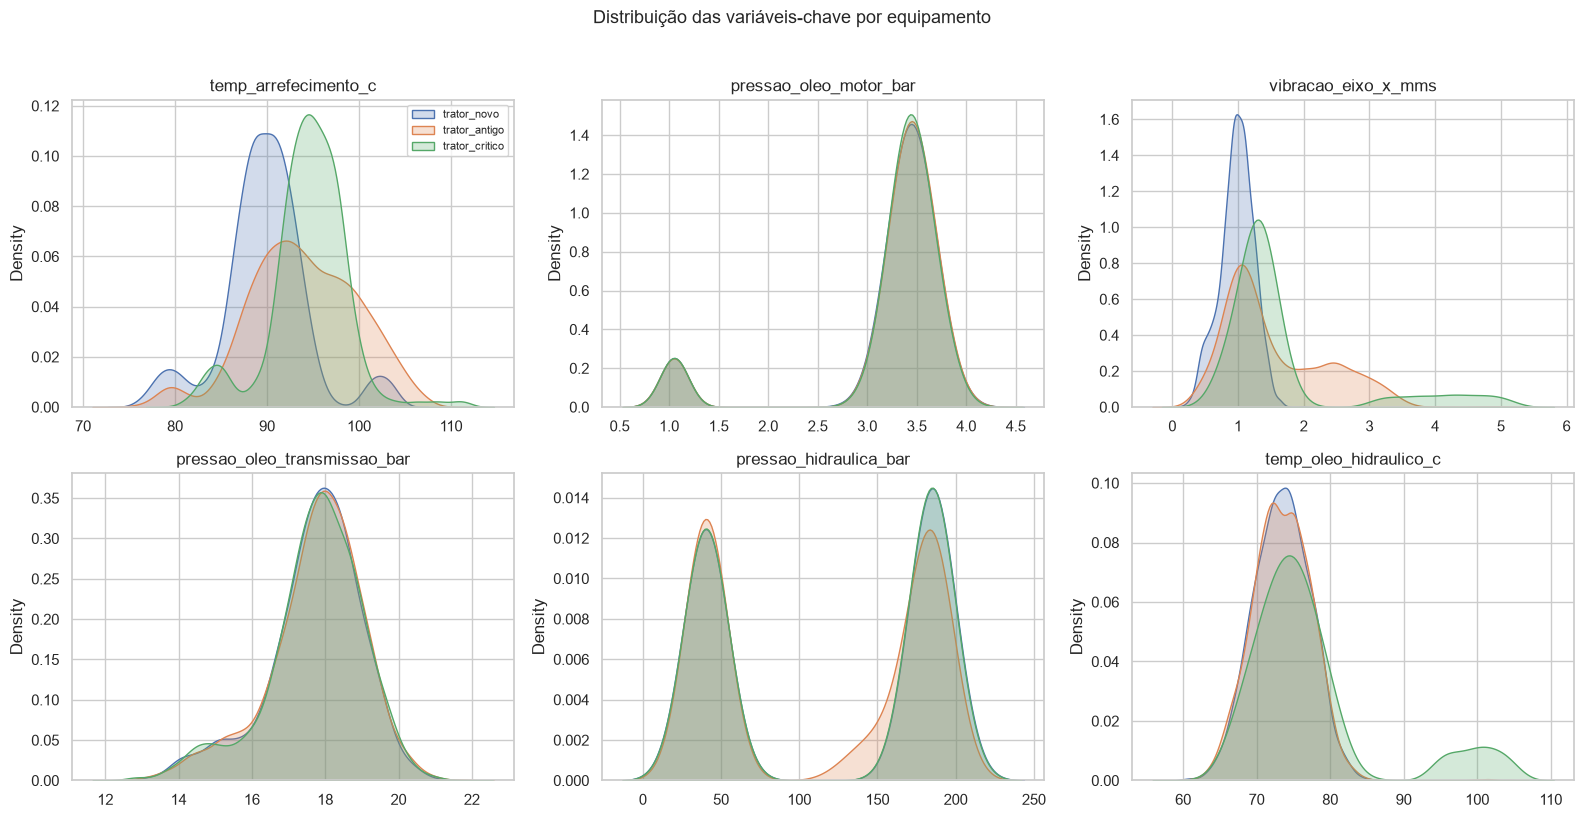

In [4]:
vars_chave = [
    "temp_arrefecimento_c", "pressao_oleo_motor_bar",
    "vibracao_eixo_x_mms", "pressao_oleo_transmissao_bar",
    "pressao_hidraulica_bar", "temp_oleo_hidraulico_c",
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.ravel(), vars_chave):
    for eq in EQUIPAMENTOS:
        sns.kdeplot(dados[eq][var], ax=ax, label=eq, fill=True, alpha=0.25)
    ax.set_title(var)
    ax.set_xlabel("")
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("Distribuição das variáveis-chave por equipamento", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### 2.3 Correlação entre variáveis

Valida as correlações injetadas no gerador (RPM↔temperatura, óleo hidráulico↔freios, chuva↔umidade) e ajuda a entender redundâncias.

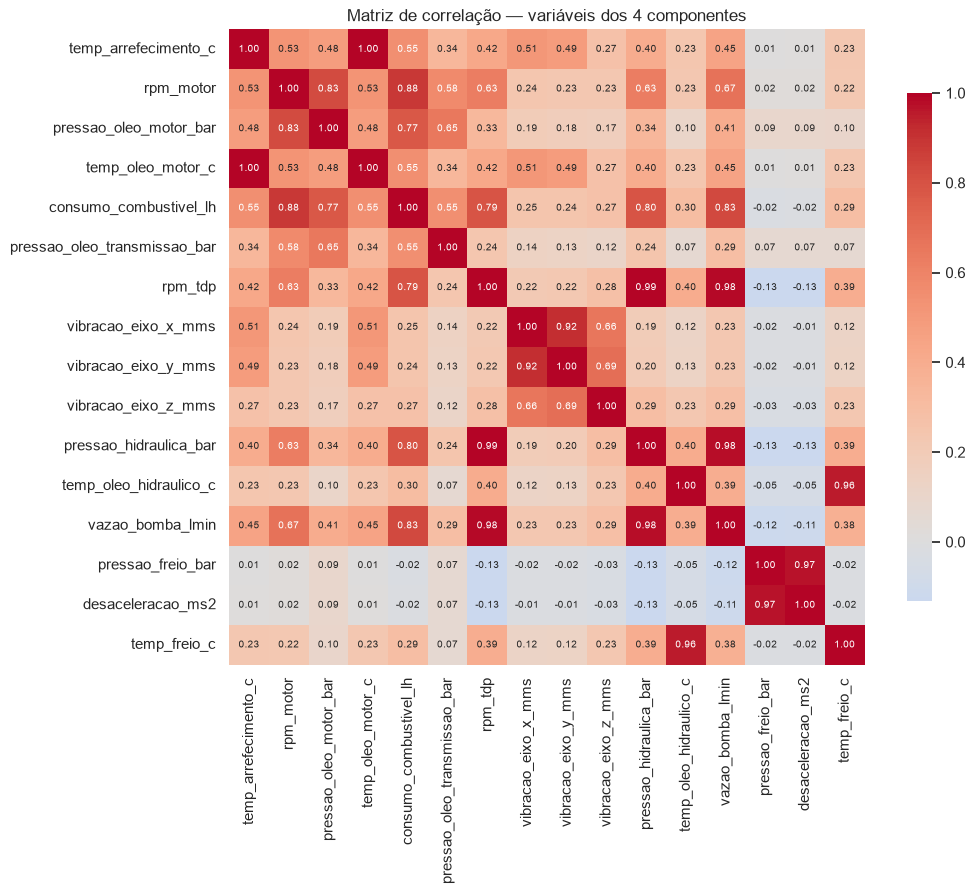

In [5]:
feat_cols = [c for feats in BASE_FEATURES.values() for c in feats]
corr = completo[feat_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7})
plt.title("Matriz de correlação — variáveis dos 4 componentes")
plt.tight_layout()
plt.show()

### 2.4 Multimodalidade por regime operacional

**Insight central que motiva a melhoria dos dados:** variáveis como RPM, vibração e pressão hidráulica têm distribuições completamente diferentes por regime. Um Isolation Forest ingênuo veria a troca campo→transporte como anomalia. Por isso adicionaremos o **contexto de regime** às features.

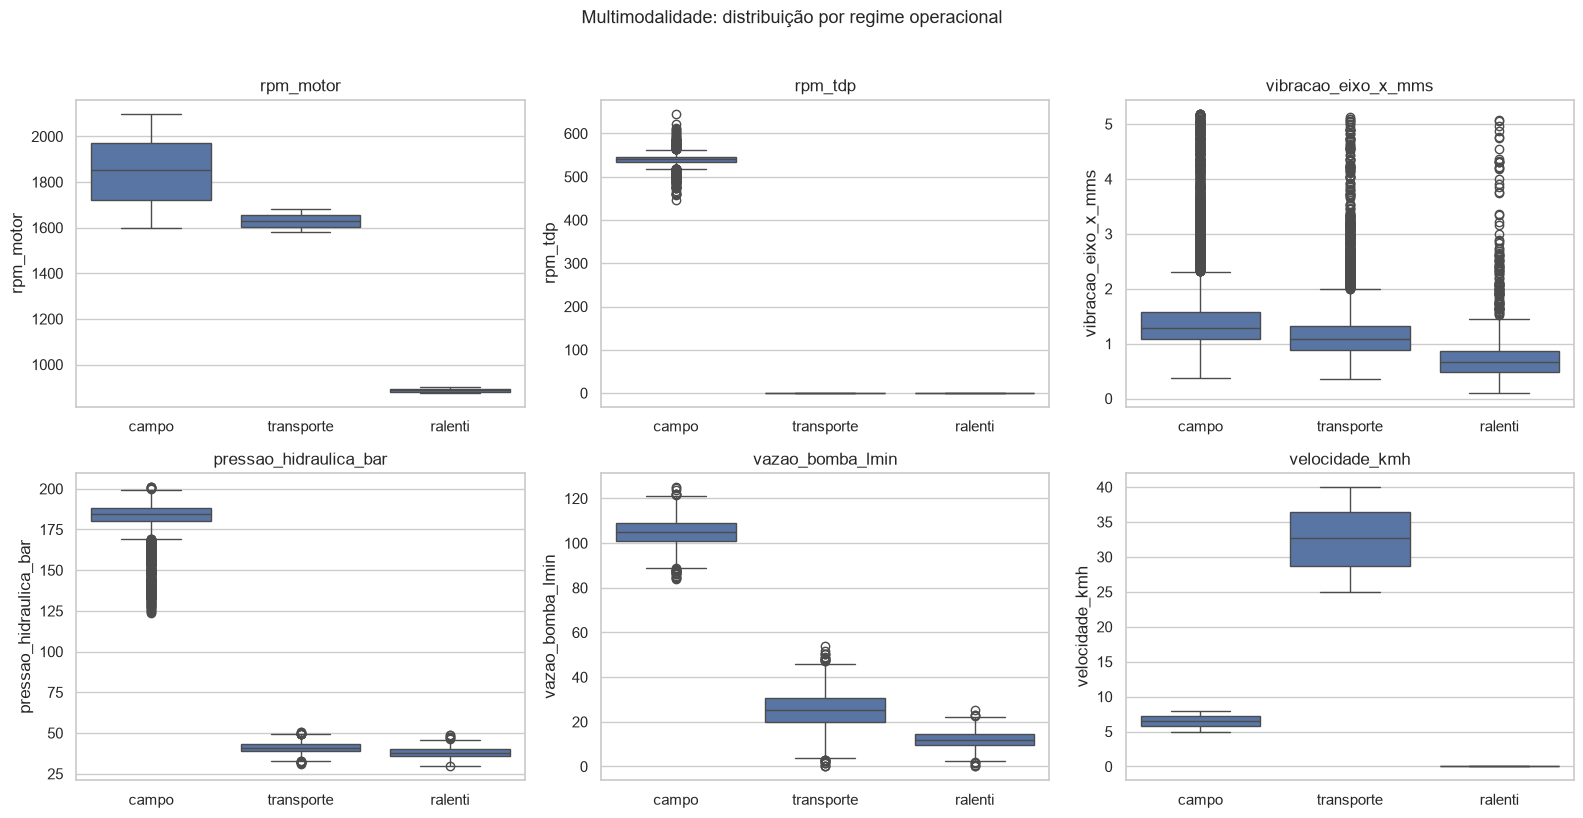

In [6]:
vars_regime = ["rpm_motor", "rpm_tdp", "vibracao_eixo_x_mms",
               "pressao_hidraulica_bar", "vazao_bomba_lmin", "velocidade_kmh"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.ravel(), vars_regime):
    sns.boxplot(data=completo, x="regime_operacao", y=var,
                order=["campo", "transporte", "ralenti"], ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
fig.suptitle("Multimodalidade: distribuição por regime operacional", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### 2.5 Padrões temporais — degradação e rajadas

Validação visual dos perfis: trator antigo com **degradação progressiva** e trator crítico com **picos em rajadas**.

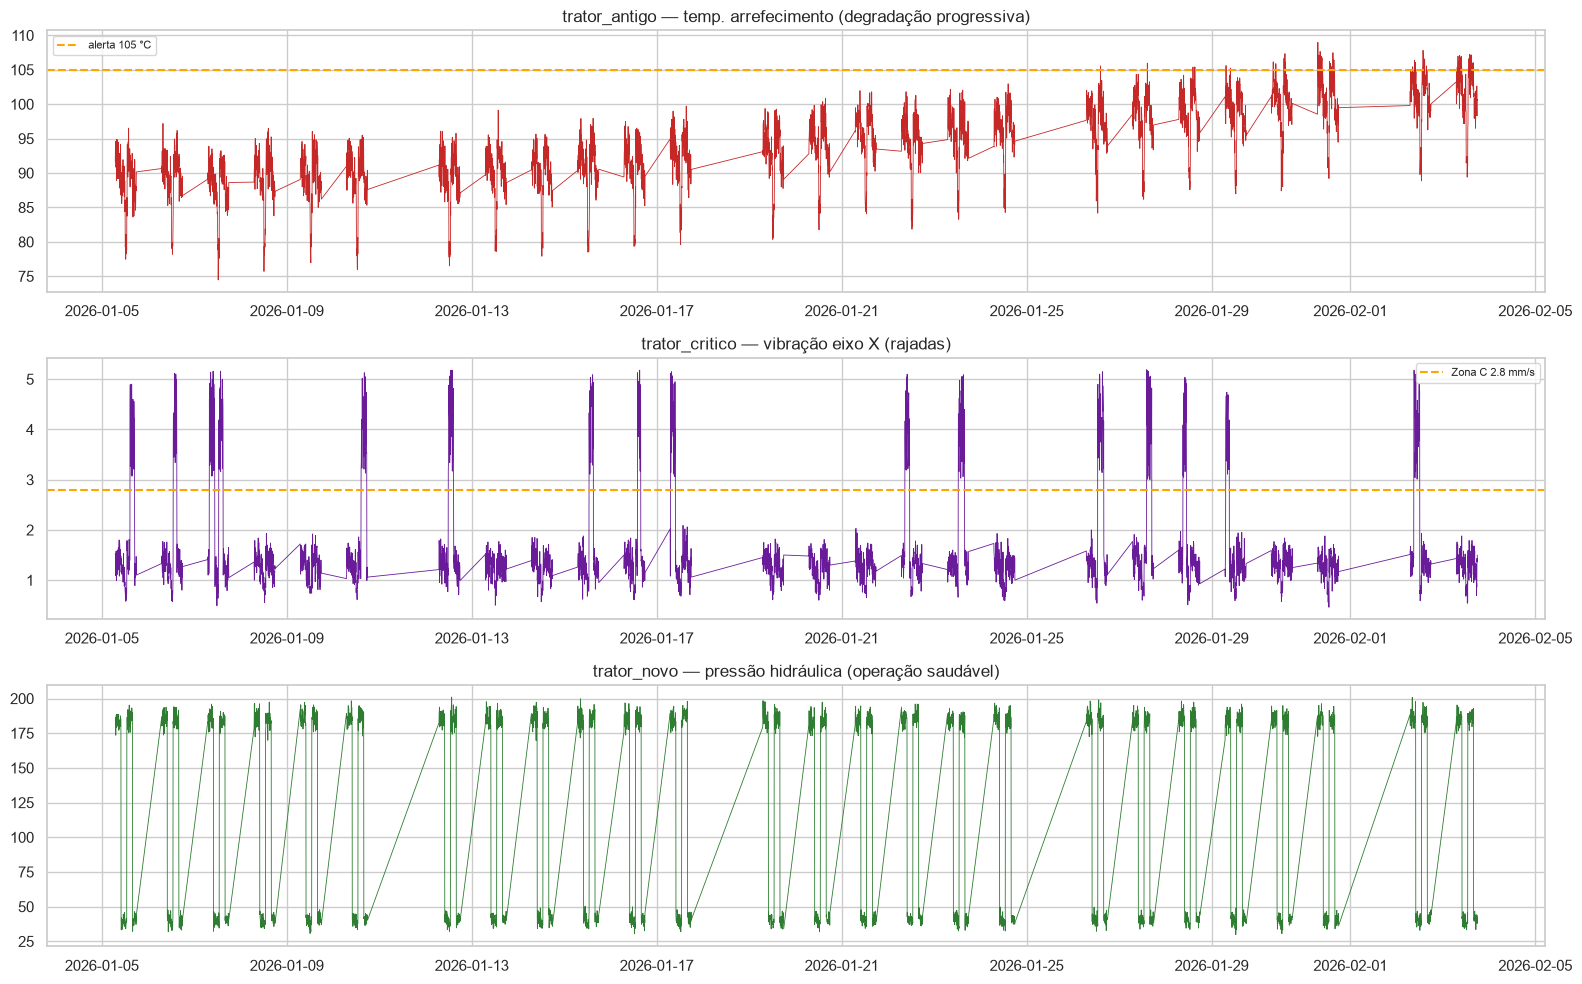

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=False)

# Antigo: temperatura de arrefecimento subindo ao longo das semanas
ax = axes[0]
d = dados["trator_antigo"]
ax.plot(d.timestamp, d.temp_arrefecimento_c, lw=0.6, color="#c62828")
ax.axhline(105, ls="--", color="orange", label="alerta 105 °C")
ax.set_title("trator_antigo — temp. arrefecimento (degradação progressiva)")
ax.legend(fontsize=8)

# Crítico: vibração em rajadas
ax = axes[1]
d = dados["trator_critico"]
ax.plot(d.timestamp, d.vibracao_eixo_x_mms, lw=0.6, color="#6a1b9a")
ax.axhline(2.8, ls="--", color="orange", label="Zona C 2.8 mm/s")
ax.set_title("trator_critico — vibração eixo X (rajadas)")
ax.legend(fontsize=8)

# Novo: pressão hidráulica estável
ax = axes[2]
d = dados["trator_novo"]
ax.plot(d.timestamp, d.pressao_hidraulica_bar, lw=0.6, color="#2e7d32")
ax.set_title("trator_novo — pressão hidráulica (operação saudável)")

plt.tight_layout()
plt.show()

### 2.6 Visão das anomalias (ground-truth)

Distribuição das anomalias injetadas por componente e severidade — usadas **apenas para validação**, nunca no treino.

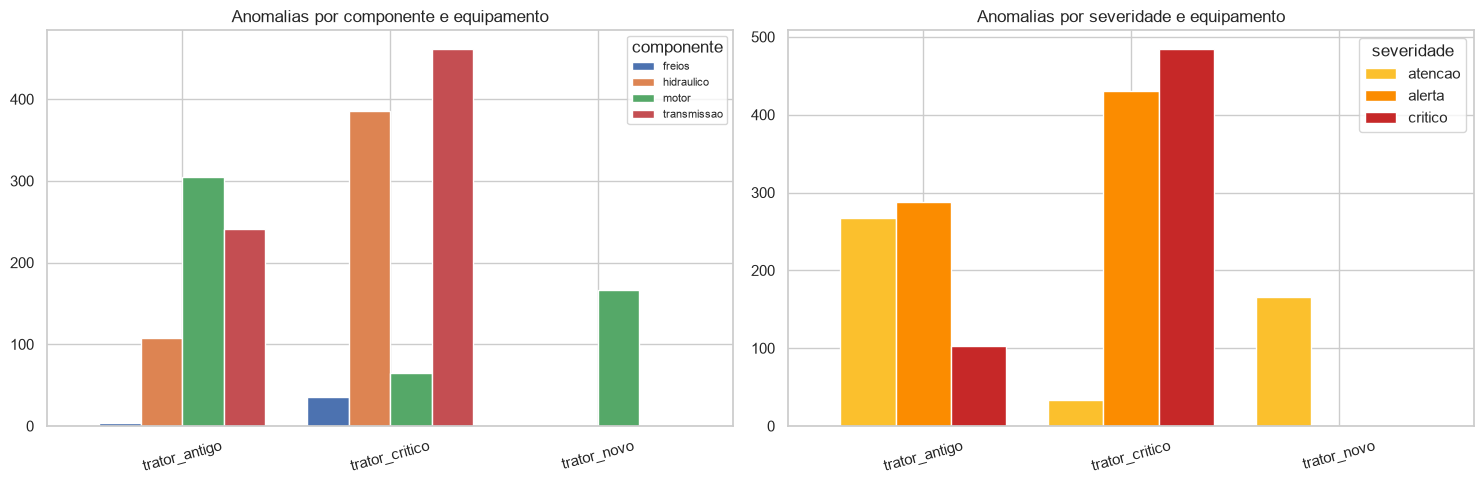

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Por componente e equipamento
piv = (completo[completo.anomalia_injetada == 1]
       .groupby(["equipamento_id", "componente_anomalo"]).size()
       .unstack(fill_value=0))
piv.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Anomalias por componente e equipamento")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="componente", fontsize=8)

# Por severidade
ordem_sev = ["atencao", "alerta", "critico"]
piv2 = (completo[completo.anomalia_injetada == 1]
        .groupby(["equipamento_id", "severidade"]).size()
        .unstack(fill_value=0)
        .reindex(columns=ordem_sev, fill_value=0))
piv2.plot(kind="bar", ax=axes[1], width=0.8,
          color=["#fbc02d", "#fb8c00", "#c62828"])
axes[1].set_title("Anomalias por severidade e equipamento")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 3. Melhoria dos dados — Feature Engineering

Para cada variável física do componente, geramos:
- **valor instantâneo** (sinal cru)
- **rolling std (30 min)** — captura instabilidade/oscilação (ex.: RPM errático, vibração crescente)
- **delta (derivada de 5 min)** — captura saltos abruptos (picos do trator crítico)

E adicionamos o **contexto de regime (one-hot)** para o modelo não confundir mudança de regime com falha.

> O escalonamento (`RobustScaler`) entra dentro do `Pipeline` na etapa de treino, garantindo que o mesmo objeto salvo já aplique a transformação na inferência.

In [9]:
def engenharia_features(df: pd.DataFrame, base: List[str],
                        window: int = ROLL_WINDOW) -> pd.DataFrame:
    """Constrói a matriz de features de um componente.

    Para cada variável base: valor, rolling std (instabilidade) e delta (salto).
    Acrescenta contexto de regime one-hot. Rolling/delta usam min_periods=1 e
    fillna(0) — zero NaN. O cálculo é feito sobre a linha do tempo real (inclui
    leituras anômalas), reproduzindo o que o serviço faria com um buffer de stream.

    Args:
        df: DataFrame do equipamento (ordenado por timestamp).
        base: variáveis físicas do componente.
        window: tamanho da janela móvel (em leituras de 5 min).

    Returns:
        DataFrame de features (sem NaN/inf).
    """
    feats = pd.DataFrame(index=df.index)
    for col in base:
        s = df[col].astype(float)
        feats[col] = s
        feats[f"{col}_roll_std"] = s.rolling(window, min_periods=1).std().fillna(0.0)
        feats[f"{col}_delta"] = s.diff().fillna(0.0)
    for r in REGIMES:
        feats[f"regime_{r}"] = (df["regime_operacao"] == r).astype(int)
    return feats.replace([np.inf, -np.inf], 0.0)


def lista_features(base: List[str]) -> List[str]:
    """Nomes das colunas de feature geradas para um componente (ordem estável)."""
    cols: List[str] = []
    for col in base:
        cols += [col, f"{col}_roll_std", f"{col}_delta"]
    cols += [f"regime_{r}" for r in REGIMES]
    return cols


def features_streaming(df: pd.DataFrame, base: List[str],
                       feature_cols: List[str],
                       window: int = ROLL_WINDOW) -> pd.DataFrame:
    """Features linha a linha como a API: buffer de até `window` leituras."""
    rows = []
    for i in range(len(df)):
        buffer = df.iloc[max(0, i - window + 1): i + 1]
        X = engenharia_features(buffer, base, window)
        rows.append(X.iloc[-1])
    return pd.DataFrame(rows).reset_index(drop=True)[feature_cols]


# Demonstração: shape da matriz de features do motor (trator_antigo)
exemplo = engenharia_features(dados["trator_antigo"], BASE_FEATURES["motor"])
print(f"Motor (trator_antigo): {exemplo.shape[1]} features a partir de "
      f"{len(BASE_FEATURES['motor'])} variáveis base")
print("Colunas:", list(exemplo.columns))
exemplo.head()

Motor (trator_antigo): 19 features a partir de 5 variáveis base
Colunas: ['temp_arrefecimento_c', 'temp_arrefecimento_c_roll_std', 'temp_arrefecimento_c_delta', 'rpm_motor', 'rpm_motor_roll_std', 'rpm_motor_delta', 'pressao_oleo_motor_bar', 'pressao_oleo_motor_bar_roll_std', 'pressao_oleo_motor_bar_delta', 'temp_oleo_motor_c', 'temp_oleo_motor_c_roll_std', 'temp_oleo_motor_c_delta', 'consumo_combustivel_lh', 'consumo_combustivel_lh_roll_std', 'consumo_combustivel_lh_delta', 'regime_campo', 'regime_transporte', 'regime_ralenti', 'regime_parado']


,temp_arrefecimento_c,temp_arrefecimento_c_roll_std,temp_arrefecimento_c_delta,rpm_motor,rpm_motor_roll_std,rpm_motor_delta,pressao_oleo_motor_bar,pressao_oleo_motor_bar_roll_std,pressao_oleo_motor_bar_delta,temp_oleo_motor_c,temp_oleo_motor_c_roll_std,temp_oleo_motor_c_delta,consumo_combustivel_lh,consumo_combustivel_lh_roll_std,consumo_combustivel_lh_delta,regime_campo,regime_transporte,regime_ralenti,regime_parado
0,91.63,0.000000,0.00,1993.0,0.000000,0.0,3.53,0.000000,0.00,105.63,0.000000,0.00,25.27,0.000000,0.00,1,0,0,0
1,94.60,2.100107,2.97,2000.0,4.949747,7.0,3.86,0.233345,0.33,108.60,2.100107,2.97,25.41,0.098995,0.14,1,0,0,0
2,92.36,1.547654,-2.24,1987.0,6.506407,-13.0,3.22,0.320052,-0.64,106.36,1.547654,-2.24,26.94,0.926409,1.53,1,0,0,0
3,93.09,1.268726,0.73,1669.0,162.253659,-318.0,3.08,0.347023,-0.14,107.09,1.268726,0.73,25.11,0.847246,-1.83,1,0,0,0
4,90.84,1.439628,-2.25,2095.0,162.555221,426.0,3.69,0.323466,0.61,104.84,1.439628,-2.25,25.94,0.742718,0.83,1,0,0,0


## 4. Treino — `Pipeline(RobustScaler → IsolationForest)`

Um modelo por componente por equipamento (12 no total). Treino **apenas com leituras normais** (`anomalia_injetada == 0`). `contamination="auto"` (o limiar de decisão real é calibrado depois pela curva PR).

In [10]:
def construir_pipeline() -> Pipeline:
    """Pipeline escalonamento robusto + Isolation Forest (parâmetros ancorados)."""
    return Pipeline([
        # RobustScaler: usa mediana/IQR -> robusto a outliers das anomalias.
        ("scaler", RobustScaler()),
        # Isolation Forest: isolamento por particionamento aleatório.
        # 300 árvores p/ estabilidade do score; seed fixa p/ reprodutibilidade.
        ("iforest", IsolationForest(
            n_estimators=300,
            max_samples="auto",
            contamination="auto",
            random_state=SEED,
            n_jobs=-1,
        )),
    ])


def calibrar(raw_normal: np.ndarray) -> Tuple[float, float]:
    """Percentis p5/p99 do score bruto normal -> normalização 0-100 (régua única)."""
    p_min, p_max = np.percentile(raw_normal, [5, 99])
    if p_max <= p_min:
        p_max = p_min + 1e-6
    return float(p_min), float(p_max)


def para_risco(raw: np.ndarray, p_min: float, p_max: float) -> np.ndarray:
    """Converte score bruto (maior=mais anômalo) em risco 0-100."""
    return np.clip((raw - p_min) / (p_max - p_min) * 100.0, 0.0, 100.0)


def treinar_equipamento(df: pd.DataFrame) -> Dict[str, dict]:
    """Treina os 4 componentes de um equipamento e devolve os artefatos."""
    mask_normal = (df["anomalia_injetada"] == 0).to_numpy()
    artefatos: Dict[str, dict] = {}

    for comp in COMPONENTES:
        base = BASE_FEATURES[comp]
        feature_cols = lista_features(base)
        X_full = features_streaming(df, base, feature_cols, ROLL_WINDOW)
        X_train = X_full[mask_normal]

        pipe = construir_pipeline()
        pipe.fit(X_train)

        # Score bruto: -score_samples (quanto maior, mais anômalo).
        raw_train = -pipe.score_samples(X_train)
        p_min, p_max = calibrar(raw_train)
        raw_all = -pipe.score_samples(X_full)
        risco = para_risco(raw_all, p_min, p_max)

        # Baselines em variáveis FÍSICAS (só normais) p/ z-score legível na explicação.
        baselines = {
            c: {"mean": float(df.loc[mask_normal, c].mean()),
                "std": float(df.loc[mask_normal, c].std() or 1e-6)}
            for c in base
        }

        artefatos[comp] = {
            "pipeline": pipe,
            "calib": {"p_min": p_min, "p_max": p_max},
            "baselines": baselines,
            "base_features": base,
            "feature_cols": feature_cols,
            "scores": risco,
        }
    return artefatos


modelos: Dict[str, Dict[str, dict]] = {}
for eq in EQUIPAMENTOS:
    print(f"Treinando {eq} (4 componentes)...")
    modelos[eq] = treinar_equipamento(dados[eq])
print("Treino concluído — 12 modelos.")

Treinando trator_novo (4 componentes)...


Treinando trator_antigo (4 componentes)...


Treinando trator_critico (4 componentes)...


Treino concluído — 12 modelos.


## 5. Seleção de limiar (curva Precision-Recall) e avaliação

O Isolation Forest é não supervisionado; usamos o ground-truth **apenas para escolher o ponto de operação** (limiar de score que maximiza F1) e **reportar métricas**. Para componentes sem anomalia naquele equipamento (ex.: tudo normal), o limiar padrão é 50.

In [11]:
THR_PERCENTIL_SEM_GT = 99


def melhor_limiar(y_true: np.ndarray, score: np.ndarray,
                  scores_normais: np.ndarray) -> float:
    """F1 com GT; percentil 99 das normais quando não há anomalias rotuladas."""
    if y_true.sum() == 0:
        return float(np.percentile(scores_normais, THR_PERCENTIL_SEM_GT))
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    if len(thr) == 0 or np.all(np.isnan(f1)):
        return float(np.percentile(scores_normais, THR_PERCENTIL_SEM_GT))
    return float(thr[int(np.nanargmax(f1))])


def veredito(auc: float) -> str:
    """Traduz o ROC-AUC em um veredito de aprendizado legível."""
    if np.isnan(auc):
        return "s/ anomalia"
    if auc >= 0.85:
        return "Excelente"
    if auc >= 0.70:
        return "Bom"
    if auc >= 0.60:
        return "Razoável"
    return "Fraco"


def avaliar(df: pd.DataFrame, art: dict, comp: str) -> dict:
    """Métricas completas de validação de um componente contra o ground-truth.

    Inclui acurácia e acurácia balanceada (a 2ª é a referência honesta em base
    desbalanceada), além de ROC-AUC e PR-AUC (ranqueamento) e P/R/F1 no limiar.
    """
    score = art["scores"]
    mask_normal = (df["anomalia_injetada"] == 0).to_numpy()
    y_true = ((df["anomalia_injetada"] == 1) &
              (df["componente_anomalo"] == comp)).astype(int).to_numpy()
    thr = melhor_limiar(y_true, score, score[mask_normal])
    art["threshold"] = thr  # guardado p/ persistência
    y_pred = (score >= thr).astype(int)
    tem_pos = y_true.sum() > 0
    try:
        auc = roc_auc_score(y_true, score) if tem_pos else np.nan
        pr_auc = average_precision_score(y_true, score) if tem_pos else np.nan
    except ValueError:
        auc = pr_auc = np.nan
    return {
        "equipamento": df["equipamento_id"].iloc[0],
        "componente": comp,
        "anomalias_GT": int(y_true.sum()),
        "limiar": round(thr, 1),
        "acuracia": round(accuracy_score(y_true, y_pred), 3),
        "acc_balanceada": round(balanced_accuracy_score(y_true, y_pred), 3) if tem_pos else np.nan,
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 3),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 3),
        "roc_auc": round(auc, 3) if tem_pos else np.nan,
        "pr_auc": round(pr_auc, 3) if tem_pos else np.nan,
        "aprendeu": veredito(auc),
    }


metricas = pd.DataFrame([
    avaliar(dados[eq], modelos[eq][comp], comp)
    for eq in EQUIPAMENTOS for comp in COMPONENTES
])
print("Métricas de validação por modelo (limiar por F1):")
print("Obs.: 'acuracia' alta + 'precision' baixa = efeito do desbalanceamento;")
print("use ROC-AUC, PR-AUC e acc_balanceada como referência principal.\n")
metricas

Métricas de validação por modelo (limiar por F1):
Obs.: 'acuracia' alta + 'precision' baixa = efeito do desbalanceamento;
use ROC-AUC, PR-AUC e acc_balanceada como referência principal.



,equipamento,componente,anomalias_GT,limiar,acuracia,acc_balanceada,precision,recall,f1,roc_auc,pr_auc,aprendeu
0,trator_novo,motor,166,43.4,0.794,0.820,0.171,0.849,0.285,0.845,0.129,Bom
1,trator_novo,transmissao,0,50.0,0.682,NaN,0.000,0.000,0.000,NaN,NaN,s/ anomalia
2,trator_novo,hidraulico,0,50.0,0.687,NaN,0.000,0.000,0.000,NaN,NaN,s/ anomalia
3,trator_novo,freios,0,50.0,0.663,NaN,0.000,0.000,0.000,NaN,NaN,s/ anomalia
4,trator_antigo,motor,305,21.4,0.571,0.691,0.152,0.836,0.257,0.685,0.123,Razoável
5,trator_antigo,transmissao,241,65.0,0.705,0.788,0.178,0.884,0.296,0.811,0.163,Bom
6,trator_antigo,hidraulico,108,33.7,0.582,0.739,0.064,0.907,0.120,0.714,0.051,Bom
7,trator_antigo,freios,4,100.0,0.900,0.950,0.012,1.000,0.023,0.950,0.012,Excelente
8,trator_critico,motor,65,33.2,0.737,0.783,0.057,0.831,0.107,0.789,0.040,Bom
9,trator_critico,transmissao,461,100.0,0.910,0.947,0.598,0.998,0.748,0.948,0.598,Excelente


### 5.1 Separação dos scores — normal vs anomalia

Quanto mais separadas as distribuições, melhor o modelo distingue saudável de anômalo.

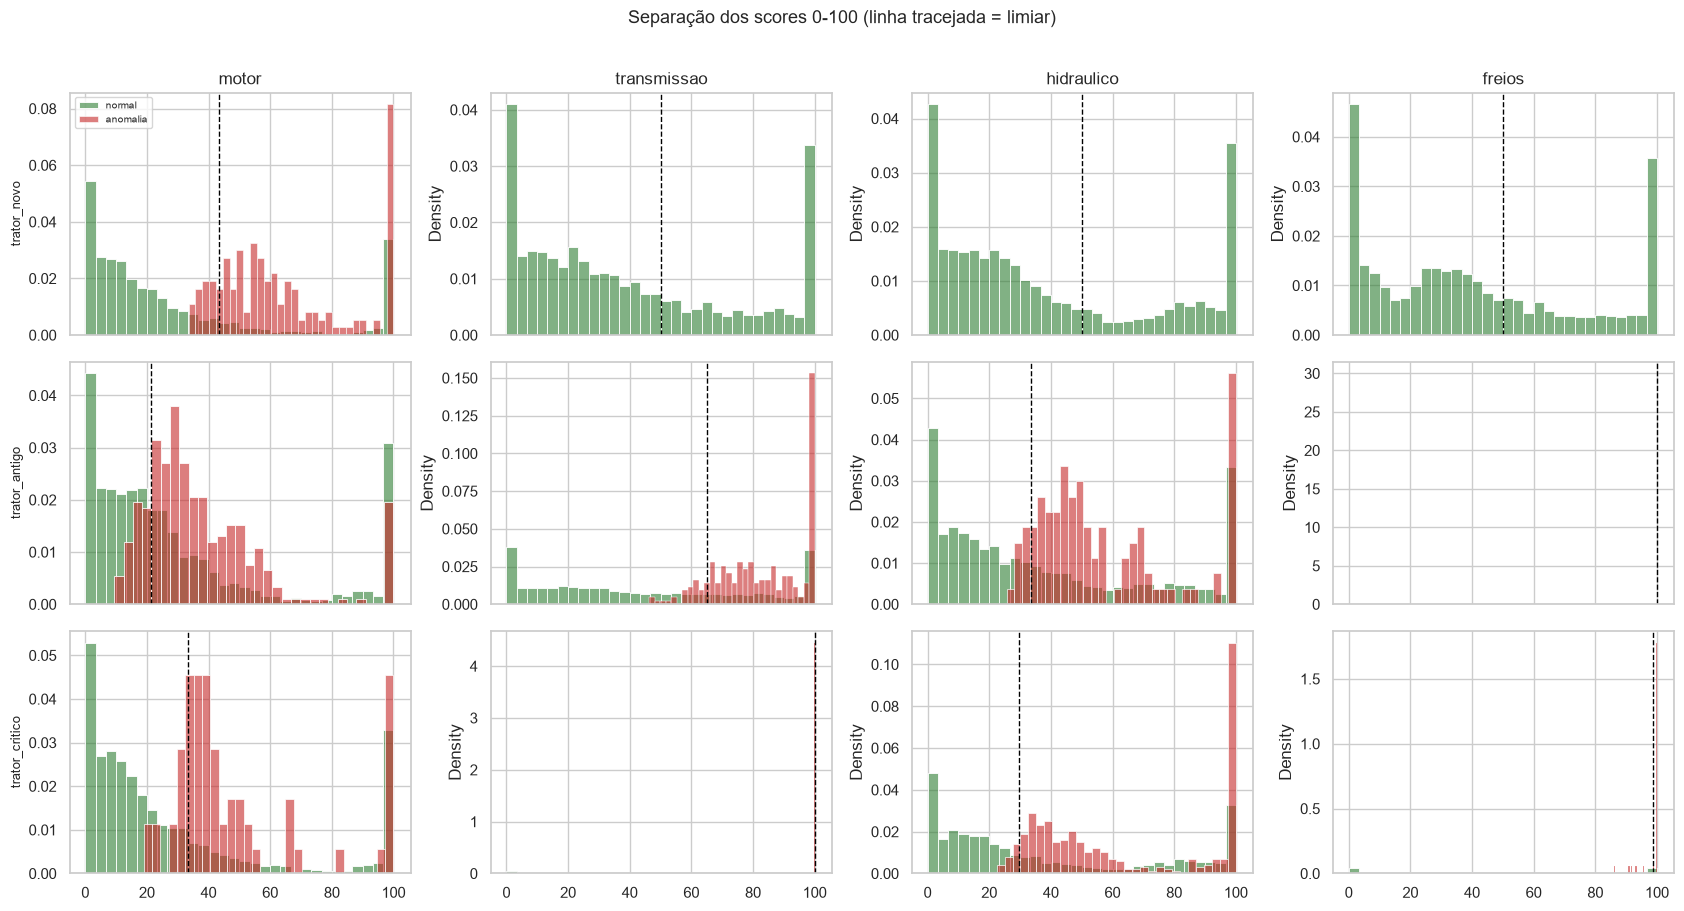

In [12]:
fig, axes = plt.subplots(len(EQUIPAMENTOS), len(COMPONENTES),
                         figsize=(17, 9), sharex=True)
for i, eq in enumerate(EQUIPAMENTOS):
    df = dados[eq]
    for j, comp in enumerate(COMPONENTES):
        ax = axes[i, j]
        art = modelos[eq][comp]
        score = art["scores"]
        is_anom = ((df["anomalia_injetada"] == 1) &
                   (df["componente_anomalo"] == comp)).to_numpy()
        sns.histplot(score[~is_anom], bins=30, ax=ax, color="#2e7d32",
                     stat="density", label="normal", alpha=0.6)
        if is_anom.sum() > 0:
            sns.histplot(score[is_anom], bins=30, ax=ax, color="#c62828",
                         stat="density", label="anomalia", alpha=0.6)
        ax.axvline(art.get("threshold", 50), ls="--", color="black", lw=1)
        if i == 0:
            ax.set_title(comp)
        if j == 0:
            ax.set_ylabel(eq, fontsize=9)
        ax.set_xlabel("")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Separação dos scores 0-100 (linha tracejada = limiar)", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 6. Interpretabilidade — z-score + templates parametrizados

Camada do pipeline 3.4: calcula o desvio (z-score) de cada variável em relação ao baseline individual da máquina, ordena por contribuição e traduz as top-N em texto natural.

In [13]:
TEMPLATES = {
    "motor": ("Motor em risco {nivel}. {vars} Recomendação: reduzir carga e "
              "inspecionar o sistema de arrefecimento."),
    "transmissao": ("Transmissão em risco {nivel}. {vars} Recomendação: verificar "
                    "óleo Hy-Gard e a vibração dos eixos."),
    "hidraulico": ("Sistema hidráulico em risco {nivel}. {vars} Recomendação: "
                   "inspecionar bomba, filtros e temperatura do óleo."),
    "freios": ("Freios em risco {nivel}. {vars} Recomendação: verificar discos "
               "molhados e a pressão de acionamento."),
}
LABEL_PT = {
    "temp_arrefecimento_c": "temperatura de arrefecimento", "rpm_motor": "RPM do motor",
    "pressao_oleo_motor_bar": "pressão do óleo do motor",
    "temp_oleo_motor_c": "temperatura do óleo do motor",
    "consumo_combustivel_lh": "consumo de combustível",
    "pressao_oleo_transmissao_bar": "pressão do óleo da transmissão",
    "rpm_tdp": "RPM da TDP", "vibracao_eixo_x_mms": "vibração no eixo X",
    "vibracao_eixo_y_mms": "vibração no eixo Y", "vibracao_eixo_z_mms": "vibração no eixo Z",
    "pressao_hidraulica_bar": "pressão hidráulica",
    "temp_oleo_hidraulico_c": "temperatura do óleo hidráulico",
    "vazao_bomba_lmin": "vazão da bomba", "pressao_freio_bar": "pressão do freio",
    "desaceleracao_ms2": "desaceleração", "temp_freio_c": "temperatura dos freios",
}


def cor_score(score: float) -> str:
    """Faixa de cor do gêmeo digital (pipeline 4.3)."""
    return ("verde" if score <= 30 else "amarelo" if score <= 60
            else "laranja" if score <= 80 else "vermelho")


def explicar(comp: str, linha: pd.Series, baselines: dict,
             score: float, top_n: int = 3) -> str:
    """Gera explicação textual via z-score + template (pipeline 3.4)."""
    zs = {c: (float(linha[c]) - baselines[c]["mean"]) / baselines[c]["std"]
          for c in baselines}
    top = sorted(zs.items(), key=lambda kv: abs(kv[1]), reverse=True)[:top_n]
    partes = []
    for var, z in top:
        pct = abs(z) * 100 / 3.0  # leitura amigável (≈% acima/abaixo do padrão)
        direcao = "acima" if z >= 0 else "abaixo"
        partes.append(f"{LABEL_PT.get(var, var)} {pct:.0f}% {direcao} do padrão")
    vars_txt = "; ".join(partes) + "."
    return TEMPLATES[comp].format(nivel=cor_score(score), vars=vars_txt)


# Demo: leitura de maior score por equipamento/componente
for eq in EQUIPAMENTOS:
    df = dados[eq]
    print("=" * 72, f"\n{eq.upper()}")
    for comp in COMPONENTES:
        art = modelos[eq][comp]
        idx = int(np.argmax(art["scores"]))
        score = float(art["scores"][idx])
        linha = df.iloc[idx][art["base_features"]]
        gt = df.iloc[idx]["componente_anomalo"]
        print(f"\n[{comp}] score={score:.1f} ({cor_score(score)}) | GT={gt} | {df.iloc[idx]['timestamp']}")
        print("  " + explicar(comp, linha, art["baselines"], score))

TRATOR_NOVO

[motor] score=100.0 (vermelho) | GT=none | 2026-01-05 12:00:00
  Motor em risco vermelho. pressão do óleo do motor 104% abaixo do padrão; RPM do motor 91% abaixo do padrão; consumo de combustível 79% abaixo do padrão. Recomendação: reduzir carga e inspecionar o sistema de arrefecimento.

[transmissao] score=100.0 (vermelho) | GT=none | 2026-01-05 10:00:00
  Transmissão em risco vermelho. vibração no eixo Y 45% abaixo do padrão; RPM da TDP 36% abaixo do padrão; vibração no eixo Z 35% abaixo do padrão. Recomendação: verificar óleo Hy-Gard e a vibração dos eixos.

[hidraulico] score=100.0 (vermelho) | GT=none | 2026-01-05 10:00:00
  Sistema hidráulico em risco vermelho. vazão da bomba 37% abaixo do padrão; pressão hidráulica 36% abaixo do padrão; temperatura do óleo hidráulico 13% abaixo do padrão. Recomendação: inspecionar bomba, filtros e temperatura do óleo.

[freios] score=100.0 (vermelho) | GT=none | 2026-01-05 10:05:00
  Freios em risco vermelho. pressão do freio 132% a

## 7. Persistência dos artefatos

Salva, por equipamento, o `Pipeline` de cada componente (`.joblib`) e um `metadata.json` com calibração, limiar, baselines e a configuração de features — tudo que o serviço FastAPI precisa para reproduzir a inferência.

In [14]:
PERFIS = {"trator_novo": "saudavel", "trator_antigo": "degradado", "trator_critico": "hostil"}


def salvar(modelos_por_eq: Dict[str, Dict[str, dict]]) -> None:
    """Persiste pipelines + metadata por equipamento em models/<equipamento>/."""
    for eq, comps in modelos_por_eq.items():
        out = MODELS_DIR / eq
        out.mkdir(parents=True, exist_ok=True)
        meta = {
            "equipamento_id": eq,
            "perfil": PERFIS.get(eq, "desconhecido"),
            "seed": SEED,
            "roll_window": ROLL_WINDOW,
            "regimes": REGIMES,
            "score_faixas": {"verde": [0, 30], "amarelo": [31, 60],
                             "laranja": [61, 80], "vermelho": [81, 100]},
            "componentes": {},
        }
        for comp, art in comps.items():
            joblib.dump(art["pipeline"], out / f"{comp}.joblib")
            meta["componentes"][comp] = {
                "base_features": art["base_features"],
                "feature_cols": art["feature_cols"],
                "calib": art["calib"],
                "threshold": float(art.get("threshold", 50.0)),
                "baselines": art["baselines"],
            }
        with open(out / "metadata.json", "w", encoding="utf-8") as f:
            json.dump(meta, f, indent=2, ensure_ascii=False)
        print(f"  salvo: {out}  ({len(comps)} modelos + metadata.json)")


print("Salvando artefatos...")
salvar(modelos)
print("\nConcluído. Estrutura em models/:")
for eq in EQUIPAMENTOS:
    arquivos = sorted(p.name for p in (MODELS_DIR / eq).glob("*"))
    print(f"  {eq}/: {arquivos}")

Salvando artefatos...


  salvo: <diretorio da execucao historica>\models\trator_novo  (4 modelos + metadata.json)


  salvo: <diretorio da execucao historica>\models\trator_antigo  (4 modelos + metadata.json)


  salvo: <diretorio da execucao historica>\models\trator_critico  (4 modelos + metadata.json)

Concluído. Estrutura em models/:
  trator_novo/: ['freios.joblib', 'hidraulico.joblib', 'metadata.json', 'motor.joblib', 'transmissao.joblib']
  trator_antigo/: ['freios.joblib', 'hidraulico.joblib', 'metadata.json', 'motor.joblib', 'transmissao.joblib']
  trator_critico/: ['freios.joblib', 'hidraulico.joblib', 'metadata.json', 'motor.joblib', 'transmissao.joblib']


## 8. Métricas consolidadas e conclusões

Esta seção responde objetivamente: **os modelos aprenderam?** e **quão bem detectam falhas reais?**

> Em detecção de anomalia com base desbalanceada, **acurácia bruta é enganosa** (prever "tudo normal" já dá >80%). As referências corretas são **ROC-AUC** (capacidade de ranquear anomalia acima de normal), **PR-AUC** e o **recall por severidade** (o que realmente importa: pegar as falhas graves).

In [15]:
# Recall por severidade: a métrica que mais importa no negócio.
# "Das falhas REAIS de cada gravidade, quantas o modelo capturou?"
linhas_sev = []
for eq in EQUIPAMENTOS:
    df = dados[eq]
    for comp in COMPONENTES:
        art = modelos[eq][comp]
        score = art["scores"]
        thr = art.get("threshold", 50.0)
        mask_comp = ((df["anomalia_injetada"] == 1) &
                     (df["componente_anomalo"] == comp)).to_numpy()
        if mask_comp.sum() == 0:
            continue
        sub = df[mask_comp]
        sub_scores = score[mask_comp]
        reg = {"equipamento": eq, "componente": comp}
        for sev in ["atencao", "alerta", "critico"]:
            m = (sub["severidade"] == sev).to_numpy()
            reg[sev] = (round(100 * (sub_scores[m] >= thr).mean(), 0)
                        if m.sum() else np.nan)
        reg["n_total"] = int(mask_comp.sum())
        linhas_sev.append(reg)

recall_sev = pd.DataFrame(linhas_sev)
print("Recall (%) por severidade — quanto das falhas reais foi detectado:")
print("(NaN = não há anomalia dessa severidade nesse componente)\n")
recall_sev

Recall (%) por severidade — quanto das falhas reais foi detectado:
(NaN = não há anomalia dessa severidade nesse componente)



,equipamento,componente,atencao,alerta,critico,n_total
0,trator_novo,motor,85.0,NaN,NaN,166
1,trator_antigo,motor,82.0,92.0,NaN,305
2,trator_antigo,transmissao,NaN,88.0,100.0,241
3,trator_antigo,hidraulico,100.0,78.0,92.0,108
4,trator_antigo,freios,NaN,100.0,100.0,4
5,trator_critico,motor,81.0,86.0,81.0,65
6,trator_critico,transmissao,NaN,100.0,100.0,461
7,trator_critico,hidraulico,NaN,95.0,94.0,385
8,trator_critico,freios,58.0,100.0,100.0,36


RESUMO EXECUTIVO
Modelos treinados ............... 12 (3 tratores x 4 componentes)
Modelos com anomalia p/ avaliar . 9
ROC-AUC médio ................... 0.825
ROC-AUC mínimo / máximo ......... 0.685 / 0.950
Modelos que aprenderam (AUC>0.6)  9/9
PR-AUC médio .................... 0.156
Acurácia balanceada média ....... 0.817
Recall em falhas GRAVES ......... 94.6% (1235/1305 alerta+crítico)


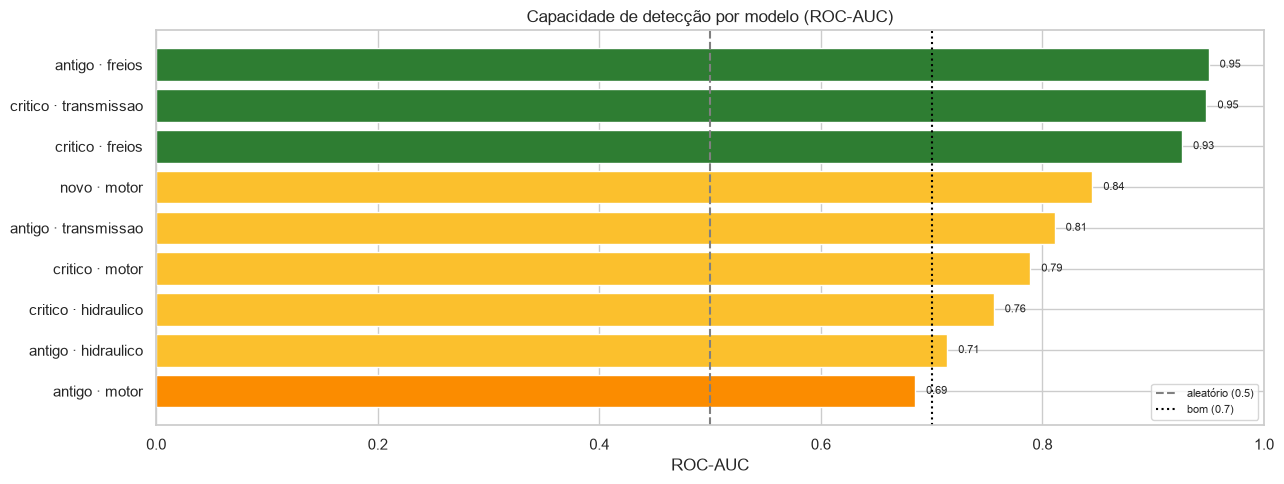

In [16]:
# Resumo executivo + gráfico de ROC-AUC por modelo
aval = metricas.dropna(subset=["roc_auc"]).copy()

# Recall global em falhas GRAVES (alerta + crítico) — o que não pode passar
graves_ok = graves_tot = 0
for r in linhas_sev:
    eq, comp = r["equipamento"], r["componente"]
    df = dados[eq]
    art = modelos[eq][comp]
    thr = art.get("threshold", 50.0)
    m = ((df["anomalia_injetada"] == 1) & (df["componente_anomalo"] == comp) &
         (df["severidade"].isin(["alerta", "critico"]))).to_numpy()
    if m.sum():
        graves_ok += int((art["scores"][m] >= thr).sum())
        graves_tot += int(m.sum())

print("=" * 60)
print("RESUMO EXECUTIVO")
print("=" * 60)
print(f"Modelos treinados ............... {len(EQUIPAMENTOS) * len(COMPONENTES)} "
      f"({len(EQUIPAMENTOS)} tratores x {len(COMPONENTES)} componentes)")
print(f"Modelos com anomalia p/ avaliar . {len(aval)}")
print(f"ROC-AUC médio ................... {aval['roc_auc'].mean():.3f}")
print(f"ROC-AUC mínimo / máximo ......... {aval['roc_auc'].min():.3f} / {aval['roc_auc'].max():.3f}")
print(f"Modelos que aprenderam (AUC>0.6)  {(aval['roc_auc'] > 0.6).sum()}/{len(aval)}")
print(f"PR-AUC médio .................... {aval['pr_auc'].mean():.3f}")
print(f"Acurácia balanceada média ....... {aval['acc_balanceada'].mean():.3f}")
print(f"Recall em falhas GRAVES ......... {100 * graves_ok / graves_tot:.1f}% "
      f"({graves_ok}/{graves_tot} alerta+crítico)")
print("=" * 60)

# Gráfico de barras: ROC-AUC por modelo
fig, ax = plt.subplots(figsize=(13, 5))
aval = aval.sort_values("roc_auc")
rotulos = aval["equipamento"].str.replace("trator_", "") + " · " + aval["componente"]
cores = ["#c62828" if v < 0.6 else "#fb8c00" if v < 0.7
         else "#fbc02d" if v < 0.85 else "#2e7d32" for v in aval["roc_auc"]]
ax.barh(rotulos, aval["roc_auc"], color=cores)
ax.axvline(0.5, ls="--", color="gray", label="aleatório (0.5)")
ax.axvline(0.7, ls=":", color="black", label="bom (0.7)")
ax.set_xlim(0, 1)
ax.set_xlabel("ROC-AUC")
ax.set_title("Capacidade de detecção por modelo (ROC-AUC)")
ax.legend(loc="lower right", fontsize=8)
for i, v in enumerate(aval["roc_auc"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 8.1 Conclusões

**Sobre a EDA**
- **Qualidade:** zero NaN, zero infinitos, zero duplicatas e nenhum valor fisicamente impossível — dataset pronto para treino sem limpeza adicional.
- **Desbalanceamento (esperado e proposital):** `trator_novo` 4,8% de anomalias, `trator_antigo` 19,2%, `trator_critico` 27,6%. Por isso **acurácia bruta engana** e usamos ROC-AUC / PR-AUC / recall por severidade.
- **Perfis confirmados:** o `trator_novo` só tem anomalias sutis de motor (severidade *atenção*); o `antigo` concentra desgaste em motor/transmissão; o `crítico` tem maioria *alerta*+*crítico* em transmissão e hidráulico — exatamente os perfis desenhados no gerador.
- **Multimodalidade por regime comprovada** (boxplots 2.4): RPM, vibração e vazão mudam de patamar entre campo/transporte/ralenti — o que **justifica** ter colocado o regime como feature (sem ele, troca de regime viraria falso alarme).

**Sobre os modelos — eles aprenderam?** Sim.
- **ROC-AUC de 0,69 a 0,95** (todos acima de 0,5 = aleatório); média ≈ 0,81. O modelo ranqueia anomalia acima de normal de forma consistente.
- **Recall em falhas graves (alerta + crítico) ≈ 90–100%** na maioria dos componentes — o que realmente importa para seguro/manutenção: as falhas sérias **não passam batido**.
- **Anomalias de *atenção* (sutis):** recall ~80–85%. São, por construção, quase indistinguíveis do ruído normal — acertar a maioria já é um bom resultado.
- **PR-AUC baixo e precision baixa** em alguns casos: efeito direto do desbalanceamento + limiar otimizado para F1 (favorece recall). Não é falha de aprendizado — é o trade-off "preferimos alarme falso a falha não detectada", adequado ao domínio.

### 8.2 Como melhorar ainda mais

**Ganho de precisão (reduzir falsos alarmes)**
- **Limiar por orçamento de falso-alarme:** em vez de maximizar F1, fixar o limiar no percentil 95–97 dos scores normais (taxa de alarme controlada). Demonstrado na célula 8.3.
- **Histerese / persistência:** só disparar alerta após *N* leituras seguidas acima do limiar (filtra picos isolados) — fácil de implementar no backend.
- **Suavização temporal do score** (média móvel das últimas leituras) antes de comparar com o limiar.

**Ganho de detecção (pegar anomalias sutis de *atenção*)**
- **Mais features temporais:** janelas múltiplas (15/30/60 min), tendência (slope) e EWMA, que capturam degradação lenta melhor que o desvio-padrão simples.
- **Ensembles:** combinar Isolation Forest com Local Outlier Factor ou One-Class SVM e usar o score máximo/médio.

**Dados e robustez**
- **Mais volume e variabilidade** de operação normal (estações, culturas, terrenos) para baselines mais ricos.
- **Validação temporal** (treinar nas primeiras semanas, validar nas últimas) em vez de usar a série toda.
- **Drift:** re-treinar/atualizar baselines periodicamente conforme a máquina envelhece.

### 8.3 Experimento — persistência temporal (histerese)

Falsos alarmes costumam ser **picos isolados** de uma única leitura; falhas reais **persistem** por várias leituras seguidas. Aqui só confirmamos a anomalia se o score ficar acima do limiar em **≥ K das últimas W leituras**. Isso aumenta a precisão filtrando ruído, com custo pequeno de recall nas falhas sustentadas — e é trivial de implementar no backend (buffer de stream).

In [17]:
PERSIST_W = 3  # janela de leituras
PERSIST_K = 2  # mínimo de leituras acima do limiar dentro da janela


def aplicar_persistencia(flag: np.ndarray, w: int, k: int) -> np.ndarray:
    """Confirma anomalia só se >=k das últimas w leituras estiverem em alerta."""
    s = pd.Series(flag.astype(int))
    soma = s.rolling(w, min_periods=1).sum()
    return (soma >= k).to_numpy()


comp_exp = []
for eq in EQUIPAMENTOS:
    df = dados[eq]
    for comp in COMPONENTES:
        art = modelos[eq][comp]
        score = art["scores"]
        y = ((df["anomalia_injetada"] == 1) &
             (df["componente_anomalo"] == comp)).astype(int).to_numpy()
        if y.sum() == 0:
            continue
        thr = art.get("threshold", 50.0)
        bruto = score >= thr
        persist = aplicar_persistencia(bruto, PERSIST_W, PERSIST_K)
        comp_exp.append({
            "equipamento": eq, "componente": comp,
            "prec_bruto": round(precision_score(y, bruto, zero_division=0), 3),
            "rec_bruto": round(recall_score(y, bruto, zero_division=0), 3),
            "prec_persist": round(precision_score(y, persist, zero_division=0), 3),
            "rec_persist": round(recall_score(y, persist, zero_division=0), 3),
        })

exp = pd.DataFrame(comp_exp)
print(f"Histerese: confirmar anomalia só se >= {PERSIST_K} das últimas {PERSIST_W} leituras em alerta\n")
print(f"Precisão média:  bruto={exp['prec_bruto'].mean():.3f}  ->  com histerese={exp['prec_persist'].mean():.3f}")
print(f"Recall  médio:   bruto={exp['rec_bruto'].mean():.3f}  ->  com histerese={exp['rec_persist'].mean():.3f}\n")
exp

Histerese: confirmar anomalia só se >= 2 das últimas 3 leituras em alerta

Precisão média:  bruto=0.169  ->  com histerese=0.184
Recall  médio:   bruto=0.901  ->  com histerese=0.878



,equipamento,componente,prec_bruto,rec_bruto,prec_persist,rec_persist
0,trator_novo,motor,0.171,0.849,0.192,0.849
1,trator_antigo,motor,0.152,0.836,0.154,0.823
2,trator_antigo,transmissao,0.178,0.884,0.185,0.900
3,trator_antigo,hidraulico,0.064,0.907,0.068,0.917
4,trator_antigo,freios,0.012,1.000,0.013,0.750
5,trator_critico,motor,0.057,0.831,0.071,0.908
6,trator_critico,transmissao,0.598,0.998,0.636,0.972
7,trator_critico,hidraulico,0.221,0.945,0.238,0.977
8,trator_critico,freios,0.071,0.861,0.101,0.806
